# Momentum vs Reversal Research

## Import Packages

In [74]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import requests

import ssl
import certifi
from io import StringIO
from tqdm.notebook import tqdm



## Data Prep

### Extract list of ASX 200 companies

In [43]:
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

url = "https://en.wikipedia.org/wiki/S%26P/ASX_200"

html = requests.get(url, headers = {"User-Agent": "Mozilla/5.0"}).text


tables = pd.read_html(StringIO(html))
tickers = tables[2]['Code']
tickers = [x + '.AX' for x in tickers]

In [65]:
prices = yf.download(tickers = [*tickers, "^AXVI"], auto_adjust = False, start='2020-01-01', end='2026-07-27')
display(prices.shape, prices.head(2))

[*******               14%                       ]  28 of 201 completed$NSR.AX: possibly delisted; no timezone found
[***********           23%                       ]  46 of 201 completed$XYX.AX: possibly delisted; no timezone found
[**********************95%*********************  ]  190 of 201 completed$IFL.AX: possibly delisted; no timezone found
[*********************100%***********************]  201 of 201 completed

3 Failed downloads:
['NSR.AX', 'XYX.AX', 'IFL.AX']: possibly delisted; no timezone found


(1661, 1206)

Price      Adj Close                                                          \
Ticker        360.AX 4DX.AX     A2M.AX AAI.AX    AFI.AX     AGL.AX    AIA.AX   
Date                                                                           
2020-01-02      3.19    NaN  13.114248    NaN  5.571769  14.504616  8.084314   
2020-01-03      3.18    NaN  13.123603    NaN  5.633937  14.511662  8.256118   

Price                                       ...  Volume                    \
Ticker         ALD.AX    ALK.AX     ALL.AX  ...  WLE.AX   WOR.AX   WOW.AX   
Date                                        ...                             
2020-01-02  25.679153  0.561122  31.331955  ...  608713   471207  1313287   
2020-01-03  25.875471  0.604285  30.965496  ...  953457  1059163  1085885   

Price                                                           
Ticker      WTC.AX  XRO.AX XYX.AX YAL.AX ZIM.AX   ZIP.AX ^AXVI  
Date                                                            
2020-01-02  658100  184388    NaN  26775  21597  1277630   0.0  
2020-01-03  574839  285107    NaN  24160    447  2240109   0.0  

[2 rows x 1206 columns]

## Data Cleaning

In [49]:
px.bar(prices.isna().sum().sort_values(ascending = False))

In [66]:
# Proportion of stocks that have NA values
na_cols_top_drop = list(prices.columns[(prices.isna().sum() > 0)])
clean_prices = prices.drop(columns = na_cols_top_drop)
display(clean_prices.shape, clean_prices.head(2))

(1661, 1044)

Price      Adj Close                                                       \
Ticker        360.AX     A2M.AX    AFI.AX     AGL.AX    AIA.AX     ALD.AX   
Date                                                                        
2020-01-02      3.19  13.114248  5.571769  14.504616  8.084314  25.679153   
2020-01-03      3.18  13.123603  5.633937  14.511662  8.256118  25.875471   

Price                                                ...  Volume           \
Ticker        ALK.AX     ALL.AX    ALQ.AX    ALX.AX  ...  WGX.AX   WHC.AX   
Date                                                 ...                    
2020-01-02  0.561122  31.331955  7.757978  4.943790  ...  763376  3415183   
2020-01-03  0.604285  30.965496  7.792041  4.981627  ...  947591  5541336   

Price                                                                        
Ticker      WLE.AX   WOR.AX   WOW.AX  WTC.AX  XRO.AX YAL.AX ZIM.AX   ZIP.AX  
Date                                                                         
2020-01-02  608713   471207  1313287  658100  184388  26775  21597  1277630  
2020-01-03  953457  1059163  1085885  574839  285107  24160    447  2240109  

[2 rows x 1044 columns]

## Channel Breakout strategy
If current days high >= past Y-day highest high, then buy

If current low <= X-days lowest low (X < Y) then exit


In [69]:
H = clean_prices['High'].to_numpy(dtype=np.float64)
L = clean_prices['Low'].to_numpy(dtype=np.float64)
C = clean_prices['Adj Close'].to_numpy(dtype=np.float64)

n_days, n_stocks = C.shape

returns = np.zeros_like(C)
returns[1:] = C[1:] / C[:-1] - 1


In [71]:
max_window = 60

highest = {}
lowest = {}

for y in range(2, max_window + 1):
    highest[y] = (
        clean_prices['High'].shift(1)
            .rolling(y)
            .max()
            .to_numpy(dtype=np.float64)
    )

for x in range(1, max_window):
    lowest[x] = (
        clean_prices['Low'].shift(1)
           .rolling(x)
           .min()
           .to_numpy(dtype=np.float64)
    )

In [155]:
def channel_breakout_sharpe_np(H, L, returns, HH, LL):
    """
    Parameters
    ----------
    H : high prices (numpy)
    L : low prices
    returns : daily returns
    HH : previous rolling highs
    LL : previous rolling lows
    """

    entry_sig = H >= HH
    exit_sig = L <= LL

    position = np.zeros(H.shape, dtype=np.int8)

    current = np.zeros(H.shape[1], dtype=np.int8) # Array for each day across each stock

    # Loop through the days
    for t in range(H.shape[0]):

        # buy
        current[entry_sig[t]] = 1

        # sell
        current[exit_sig[t]] = 0

        position[t] = current

    warmup = np.isnan(HH) | np.isnan(LL)
    strat = returns * np.roll(position, 1, axis=0)
    strat[warmup] = np.nan
    strat[0] = 0

    mean = np.nanmean(strat, axis=0)
    std = np.nanstd(strat, axis=0)

    sharpe = np.divide(
        mean,
        std,
        out=np.full_like(mean, np.nan),
        where=std > 0
    )

    sharpe *= np.sqrt(252)

    return np.nanmean(sharpe), strat

In [156]:
heatmap = np.full((max_window, max_window), np.nan)

for X in tqdm(range(1, max_window)):

    LL = lowest[X]

    for Y in range(X + 1, max_window + 1):

        HH = highest[Y]

        heatmap[X-1, Y-1], _ = channel_breakout_sharpe_np(
            H,
            L,
            returns,
            HH,
            LL
        )

  0%|          | 0/59 [00:00<?, ?it/s]

In [140]:
_, strategy = channel_breakout_sharpe_np(
    H,L,returns, highest[2], lowest[2]
)

In [143]:
strategy.shape

(1661, 174)

In [153]:
strat_rets = pd.DataFrame(columns=clean_prices['Adj Close'].columns, data=np.cumsum(strategy, axis = 0), index=clean_prices['Adj Close'].index)
strat_rets

Ticker,360.AX,A2M.AX,AFI.AX,AGL.AX,AIA.AX,ALD.AX,ALK.AX,ALL.AX,ALQ.AX,ALX.AX,...,WGX.AX,WHC.AX,WLE.AX,WOR.AX,WOW.AX,WTC.AX,XRO.AX,YAL.AX,ZIM.AX,ZIP.AX
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-07,0.000000,0.000000,0.008287,0.000000,0.008000,0.020081,-0.045802,0.000000,0.000000,0.002491,...,-0.021097,0.000000,0.000000,0.005006,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-08,0.000000,0.000000,0.002808,0.000000,0.017070,0.038626,-0.037802,-0.004367,0.000000,-0.003721,...,-0.021097,0.000000,-0.011905,0.003761,0.008392,-0.032595,-0.016943,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-20,1.558761,-0.464777,0.274092,0.156504,-0.190533,0.412007,1.076758,-0.306890,0.681078,0.025810,...,1.272086,1.113729,0.299712,0.502479,0.264550,0.897257,-0.738143,1.520639,1.750774,1.949638
2026-07-21,1.558761,-0.469032,0.266856,0.144499,-0.196104,0.416752,1.076758,-0.302716,0.681078,0.027774,...,1.272086,1.113729,0.288921,0.495980,0.268364,0.897257,-0.738143,1.543527,1.750774,1.949638
2026-07-22,1.558761,-0.469032,0.266856,0.144499,-0.200306,0.438007,1.076758,-0.311030,0.681078,0.027774,...,1.272086,1.128337,0.296194,0.495980,0.263045,0.897257,-0.738143,1.593441,1.789030,1.949638


In [154]:
px.line(strat_rets)

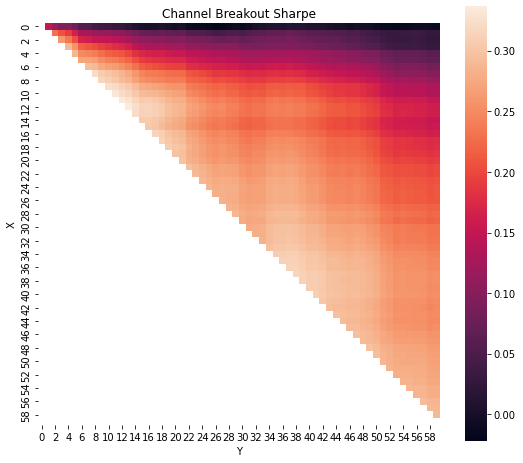

In [157]:
mask = np.tril(np.ones_like(heatmap, dtype=bool))

plt.figure(figsize=(9,8))

sns.heatmap(
    heatmap,
    mask=mask,
    cmap="rocket",
    square=True,
    xticklabels=2,
    yticklabels=2
)

plt.xlabel("Y")
plt.ylabel("X")
plt.title("Channel Breakout Sharpe")
plt.show()

## Bollinger Bands

Choose a certain level of MA as the 'average' and a level of standard deviations away from this MA. When the stock breaks the upper bound, short, when it breaks the lower bound, then buy it


In [158]:
def bollinger_sharpe_np(H, L, returns, upper, lower):
    """
    Parameters
    ----------
    H, L      : high / low prices (numpy, shape [days, stocks])
    returns   : daily returns (numpy, same shape)
    upper     : upper band, already shifted 1 day forward (no lookahead)
    lower     : lower band, already shifted 1 day forward
    """
    entry_sig = H >= upper
    exit_sig = L <= lower
 
    position = np.zeros(H.shape, dtype=np.int8)
    current = np.zeros(H.shape[1], dtype=np.int8)
 
    for t in range(H.shape[0]):
        current[entry_sig[t]] = 1
        current[exit_sig[t]] = 0
        position[t] = current
 
    strat = returns * np.roll(position, 1, axis=0)
    strat[0] = 0
 
    # mask out days where the bands aren't defined yet (rolling warmup)
    warmup = np.isnan(upper) | np.isnan(lower)
    strat[warmup] = np.nan
 
    mean = np.nanmean(strat, axis=0)
    std = np.nanstd(strat, axis=0)
 
    sharpe = np.divide(
        mean,
        std,
        out=np.full_like(mean, np.nan),
        where=std > 0,
    )
    sharpe *= np.sqrt(252)
 
    return np.nanmean(sharpe)

In [162]:
windows = range(10, 200, 2)          # MA window lengths to test
k_values = np.round(np.arange(1.0, 3.01, 0.25), 2)  # band widths (std devs)
 
close_df = clean_prices['Adj Close']
 
rolling_stats = {}
for w in windows:
    ma = close_df.rolling(w).mean().shift(1)
    sd = close_df.rolling(w).std().shift(1)
    rolling_stats[w] = (
        ma.to_numpy(dtype=np.float64),
        sd.to_numpy(dtype=np.float64),
    )

In [163]:
heatmap = np.full((len(k_values), len(windows)), np.nan)
 
for i, k in enumerate(tqdm(k_values)):
    for j, w in enumerate(windows):
        ma, sd = rolling_stats[w]
        upper = ma + k * sd
        lower = ma - k * sd
        heatmap[i, j] = bollinger_sharpe_np(H, L, returns, upper, lower)

  0%|          | 0/9 [00:00<?, ?it/s]

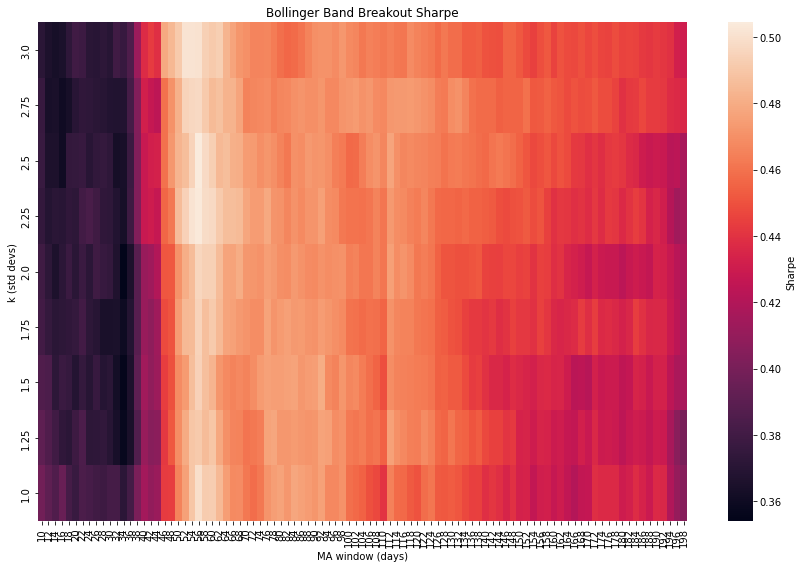

In [164]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    heatmap,
    xticklabels=list(windows),
    yticklabels=k_values,
    cmap="rocket",
    cbar_kws={"label": "Sharpe"},
)
plt.gca().invert_yaxis()
plt.xlabel("MA window (days)")
plt.ylabel("k (std devs)")
plt.title("Bollinger Band Breakout Sharpe")
plt.tight_layout()
plt.savefig("bollinger_sharpe_heatmap.png", dpi=150)
plt.show()

## VIX Analysis

In [213]:
NUM_PERCENTILES = 10

In [214]:
# Align AXVI to the same date index as clean_prices, then bucket into deciles.
axvi_aligned = prices['Adj Close']['^AXVI']
decile_labels = pd.qcut(axvi_aligned, NUM_PERCENTILES, labels=False, duplicates="drop")
decile_labels = decile_labels.to_numpy()  # shape (n_days,), values 0-9 (NaN where AXVI missing)

In [215]:
px.line(prices['Adj Close']['^AXVI'])

In [216]:
px.line(decile_labels)

In [222]:
def channel_breakout_strat(H, L, returns, HH, LL):
    entry_sig = H >= HH
    exit_sig = L <= LL
 
    position = np.zeros(H.shape, dtype=np.int8)
    current = np.zeros(H.shape[1], dtype=np.int8)
    for t in range(H.shape[0]):
        current[entry_sig[t]] = 1
        current[exit_sig[t]] = 0
        position[t] = current
 
    strat = returns * np.roll(position, 1, axis=0)
    strat[0] = 0
 
    warmup = np.isnan(HH) | np.isnan(LL)
    strat[warmup] = np.nan
    return strat, position
 
 
def bollinger_strat(H, L, returns, upper, lower):
    entry_sig = H >= upper
    exit_sig = L <= lower
 
    position = np.zeros(H.shape, dtype=np.int8)
    current = np.zeros(H.shape[1], dtype=np.int8)
    for t in range(H.shape[0]):
        current[entry_sig[t]] = 1
        current[exit_sig[t]] = 0
        position[t] = current
 
    strat = returns * np.roll(position, 1, axis=0)
    strat[0] = 0
 
    warmup = np.isnan(upper) | np.isnan(lower)
    strat[warmup] = np.nan
    return strat, position

In [223]:

def build_trade_decile_grid(position, decile_labels):
    """
    position       : (days, stocks) 0/1 array, unlagged (as built above)
    decile_labels  : (days,) array of AXVI decile 0..9 (NaN allowed)
 
    Returns a (days, stocks) grid, aligned to strat's day index (i.e.
    already shifted to match strat's lagged-position convention), giving
    the AXVI decile of the day the CURRENTLY ACTIVE trade was entered.
    NaN wherever the stock is flat that day.
    """
    prev_position = np.roll(position, 1, axis=0)
    prev_position[0] = 0
    entry_mask = (position == 1) & (prev_position == 0)
 
    # place the entry day's decile at each entry day, NaN everywhere else
    decile_broadcast = np.broadcast_to(
        decile_labels[:, None].astype(float), position.shape
    )
    entry_decile = np.where(entry_mask, decile_broadcast, np.nan)
 
    # forward-fill down each column so the entry decile persists for the
    # life of the trade, then blank out anything outside an open position
    trade_decile = pd.DataFrame(entry_decile).ffill(axis=0).to_numpy()
    trade_decile = np.where(position == 1, trade_decile, np.nan)
 
    # shift by 1 day to match strat's convention (strat[t] depends on
    # position[t-1]), so the decile label lines up with the day the
    # return is actually realised
    trade_decile_for_strat = np.roll(trade_decile, 1, axis=0)
    trade_decile_for_strat[0] = np.nan
    return trade_decile_for_strat

In [224]:
def sharpe_by_decile(strat, decile_grid, n_deciles=NUM_PERCENTILES):
    """
    strat        : (days, stocks) daily return matrix, NaN where flat/warmup
    decile_grid  : (days, stocks) array giving the entry-trade AXVI decile
                   for each element of strat (see build_trade_decile_grid),
                   NaN where flat. Elementwise -- each stock can be in a
                   different decile bucket on the same day, since trades
                   open at different times.
    Returns an array of length n_deciles: annualized Sharpe within each
    AXVI decile, averaged across stocks, computed ONLY over days each
    stock was actually in an open trade entered during that decile.
    """
    out = np.full(n_deciles, np.nan)
    for d in range(n_deciles):
        masked = np.where(decile_grid == d, strat, np.nan)
        if np.isnan(masked).all():
            continue
        mean = np.nanmean(masked, axis=0)
        std = np.nanstd(masked, axis=0)
        sharpe = np.divide(
            mean, std,
            out=np.full_like(mean, np.nan),
            where=std > 0,
        )
        sharpe *= np.sqrt(252)
        out[d] = np.nanmean(sharpe)
    return out

In [225]:
MAX_WINDOW = 60

highest = {}
lowest = {}
for y in range(2, MAX_WINDOW + 1):
    highest[y] = clean_prices['High'].shift(1).rolling(y).max().to_numpy(dtype=np.float64)
for x in range(1, MAX_WINDOW):
    lowest[x] = clean_prices['Low'].shift(1).rolling(x).min().to_numpy(dtype=np.float64)
 
# one heatmap per decile
cb_heatmaps = [np.full((MAX_WINDOW, MAX_WINDOW), np.nan) for _ in range(NUM_PERCENTILES)]
 
for X in tqdm(range(1, MAX_WINDOW), desc="channel breakout grid"):
    LL = lowest[X]
    for Y in range(X + 1, MAX_WINDOW + 1):
        HH = highest[Y]
        strat, position = channel_breakout_strat(H, L, returns, HH, LL)
        trade_decile_grid = build_trade_decile_grid(position, decile_labels)
        decile_sharpes = sharpe_by_decile(strat, trade_decile_grid)
        for d in range(NUM_PERCENTILES):
            cb_heatmaps[d][X - 1, Y - 1] = decile_sharpes[d]

channel breakout grid:   0%|          | 0/59 [00:00<?, ?it/s]

/var/folders/qs/8x4v11hj4bz599cj8rddrkbm0000gn/T/ipykernel_54417/2677656633.py:18: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning:

Degrees of freedom <= 0 for slice.



In [228]:
windows = range(10, 200, 2)
k_values = np.round(np.arange(1.0, 3.01, 0.25), 2)
 
close_df = clean_prices['Adj Close']
rolling_stats = {}
for w in windows:
    ma = close_df.rolling(w).mean().shift(1)
    sd = close_df.rolling(w).std().shift(1)
    rolling_stats[w] = (ma.to_numpy(dtype=np.float64), sd.to_numpy(dtype=np.float64))
 
bb_heatmaps = [np.full((len(k_values), len(windows)), np.nan) for _ in range(NUM_PERCENTILES)]
 
for i, k in enumerate(tqdm(k_values, desc="bollinger grid")):
    for j, w in enumerate(windows):
        ma, sd = rolling_stats[w]
        upper = ma + k * sd
        lower = ma - k * sd
        strat, position = bollinger_strat(H, L, returns, upper, lower)
        trade_decile_grid = build_trade_decile_grid(position, decile_labels)
        decile_sharpes = sharpe_by_decile(strat, trade_decile_grid)
        for d in range(NUM_PERCENTILES):
            bb_heatmaps[d][i, j] = decile_sharpes[d]

bollinger grid:   0%|          | 0/9 [00:00<?, ?it/s]

/var/folders/qs/8x4v11hj4bz599cj8rddrkbm0000gn/T/ipykernel_54417/2677656633.py:18: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning:

Degrees of freedom <= 0 for slice.



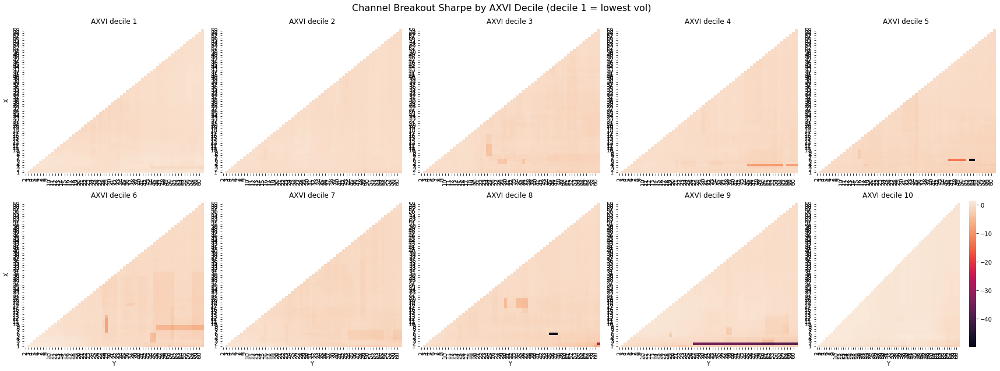

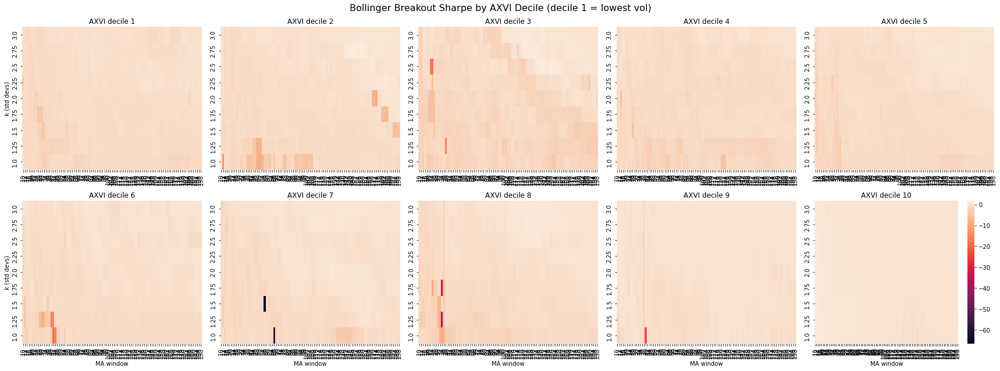

In [229]:
def plot_decile_grid(heatmaps, xticklabels, yticklabels, xlabel, ylabel, suptitle, fname):
    vmin = np.nanmin([np.nanmin(hm) for hm in heatmaps])
    vmax = np.nanmax([np.nanmax(hm) for hm in heatmaps])
 
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    for d, ax in enumerate(axes.flat):
        sns.heatmap(
            heatmaps[d],
            xticklabels=xticklabels,
            yticklabels=yticklabels,
            cmap="rocket",
            vmin=vmin,
            vmax=vmax,
            cbar=(d == NUM_PERCENTILES - 1),
            ax=ax,
        )
        ax.invert_yaxis()
        ax.set_title(f"AXVI decile {d + 1}")
        if d % 5 == 0:
            ax.set_ylabel(ylabel)
        if d >= 5:
            ax.set_xlabel(xlabel)
 
    fig.suptitle(suptitle, fontsize=16)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()
 
 
plot_decile_grid(
    cb_heatmaps,
    xticklabels=list(range(2, MAX_WINDOW + 1)),
    yticklabels=list(range(1, MAX_WINDOW)),
    xlabel="Y",
    ylabel="X",
    suptitle="Channel Breakout Sharpe by AXVI Decile (decile 1 = lowest vol)",
    fname="channel_breakout_by_decile.png",
)
 
plot_decile_grid(
    bb_heatmaps,
    xticklabels=list(windows),
    yticklabels=k_values,
    xlabel="MA window",
    ylabel="k (std devs)",
    suptitle="Bollinger Breakout Sharpe by AXVI Decile (decile 1 = lowest vol)",
    fname="bollinger_by_decile.png",
)